<div style="color:#1b365d; border-top: 5px solid #1976D2; border-bottom: 5px solid #1976D2; padding: 6px; text-align: center">
    <h2>Cuaderno 1: Gestión y Comparativa de Experimentos con MLflow (SVM y Random Forest)</h2>
</div>

**Materia:** Aprendizaje Automático | **Docente:** Ing. Remigio Hurtado, PhD.
**Dataset:** FreshRetailNet-50K | **Objetivo:** Ejecutar, registrar y guardar 6 experimentos (SVM y RF) en MLflow evaluando RMSE.

### 1. Importación de Librerías y Configuración del Servidor MLflow
Configuración de la base de datos SQLite de MLflow y creación del experimento para rastrear modelos y métricas.

In [1]:
import os
import json
import pickle
from time import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import mlflow
import mlflow.sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

BASE_DIR = 'PROJECT' if os.path.exists('PROJECT/data/sales_history.csv') else '.'
MODELS_DIR = os.path.join(BASE_DIR, 'modelos')
ARTIFACTS_DIR = os.path.join(BASE_DIR, 'artefactos_mlflow')
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

DB_PATH = os.path.abspath(os.path.join(BASE_DIR, 'mlflow.db')).replace('\\', '/')
MLRUNS_PATH = os.path.abspath(os.path.join(BASE_DIR, 'mlruns')).replace('\\', '/')
mlflow.set_tracking_uri(f"sqlite:///{DB_PATH}")

EXPERIMENT_NAME = "Experimentos_Demanda_RF_vs_SVM_Retail"
exp = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
if exp is None:
    mlflow.create_experiment(EXPERIMENT_NAME, artifact_location=f"file:///{MLRUNS_PATH}")
mlflow.set_experiment(EXPERIMENT_NAME)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print(f"MLflow {mlflow.__version__} activo | Experimento: '{EXPERIMENT_NAME}'")

MLflow 3.10.1 activo | Experimento: 'Experimentos_Demanda_RF_vs_SVM_Retail'


### 2. Preparación de Datos y Pipeline Base
Incluimos `product_id` y `categoria` junto a las variables exógenas para capturar la escala real de cada producto.
Partición estratificada 80/20 por producto garantizando representación equilibrada de los 10 artículos.

In [2]:
df_sales = pd.read_csv(os.path.join(BASE_DIR, 'data', 'sales_history.csv'))
df_sales['fecha'] = pd.to_datetime(df_sales['fecha_venta'])
df_sales['dia_semana'] = df_sales['fecha'].dt.dayofweek
df_sales['es_fin_de_semana'] = (df_sales['dia_semana'] >= 5).astype(int)

features_num = ['stock_en_momento', 'discount', 'temperatura', 'dia_semana', 'es_fin_de_semana', 'holiday_flag']
features_cat = ['product_id', 'categoria']

X = df_sales[features_num + features_cat].copy()
X['product_id'] = X['product_id'].astype(str)
y = df_sales['cantidad_vendida'].values

preprocesador = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), features_num),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), features_cat)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=X['product_id']
)
print(f"Entrenamiento: {X_train.shape[0]} muestras | Prueba: {X_test.shape[0]} muestras")

# Registro directo en la pestaña 'Datasets' de MLflow UI (sales_history.csv e inventory.csv)
df_inv = pd.read_csv(os.path.join(BASE_DIR, 'data', 'inventory.csv'))
client_ds = mlflow.tracking.MlflowClient()
for old_d in client_ds.search_datasets():
    client_ds.delete_dataset(old_d.dataset_id)

exp_id = mlflow.get_experiment_by_name(EXPERIMENT_NAME).experiment_id
ds_sales = client_ds.create_dataset(name='FreshRetailNet_50K_sales_history', experiment_id=[exp_id], tags={'archivo': 'data/sales_history.csv', 'filas': '600'})
ds_sales.merge_records([{'inputs': r[['product_id', 'nombre', 'categoria', 'fecha_venta', 'stock_en_momento', 'discount', 'holiday_flag', 'temperatura']].to_dict(), 'expectations': {'cantidad_vendida': int(r['cantidad_vendida'])}} for _, r in df_sales.head(100).iterrows()])

ds_inv = client_ds.create_dataset(name='FreshRetailNet_50K_inventory', experiment_id=[exp_id], tags={'archivo': 'data/inventory.csv', 'productos': '10'})
ds_inv.merge_records([{'inputs': r[['product_id', 'nombre', 'categoria', 'unidad', 'fecha_expiracion']].to_dict(), 'expectations': {'stock_actual': int(r['stock_actual'])}} for _, r in df_inv.iterrows()])
print('Datasets registrados en la pestaña Datasets de MLflow UI:', [d.name for d in client_ds.search_datasets()])

Entrenamiento: 480 muestras | Prueba: 120 muestras


### 3. Ejecución y Guardado de los 6 Experimentos en MLflow (4 Kernels SVM + 2 Random Forest)
Se entrenan y registran 6 experimentos descriptivos guardando parámetros, métricas (RMSE, MAE, R²), figuras y modelos.
Todos los modelos se almacenan tanto en MLflow como en la carpeta local `modelos/` para su uso en predicción.

In [3]:
def construir_pipeline_regresion(estimador):
    pipe = Pipeline([('prep', preprocesador), ('reg', estimador)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

experimentos_config = {
    "Exp1_SVM_Kernel_Lineal": {
        "familia": "SVM",
        "estimador": SVR(kernel='linear', C=1.0, epsilon=0.05),
        "params": {"algoritmo": "SVR", "kernel": "linear", "C": 1.0, "epsilon": 0.05}
    },
    "Exp2_SVM_Kernel_Polinomico_d2": {
        "familia": "SVM",
        "estimador": SVR(kernel='poly', degree=2, C=5.0, gamma='scale', epsilon=0.05),
        "params": {"algoritmo": "SVR", "kernel": "poly", "degree": 2, "C": 5.0, "gamma": "scale", "epsilon": 0.05}
    },
    "Exp3_SVM_Kernel_RBF_Gaussiano": {
        "familia": "SVM",
        "estimador": SVR(kernel='rbf', C=5.0, gamma=0.02, epsilon=0.05),
        "params": {"algoritmo": "SVR", "kernel": "rbf", "C": 5.0, "gamma": 0.02, "epsilon": 0.05}
    },
    "Exp4_SVM_Kernel_Sigmoide": {
        "familia": "SVM",
        "estimador": SVR(kernel='sigmoid', C=0.5, gamma=0.05, epsilon=0.1),
        "params": {"algoritmo": "SVR", "kernel": "sigmoid", "C": 0.5, "gamma": 0.05, "epsilon": 0.1}
    },
    "Exp5_RandomForest_Base_100": {
        "familia": "RandomForest",
        "estimador": RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1),
        "params": {"algoritmo": "RandomForest", "n_estimators": 100, "max_depth": 8, "min_samples_split": 2}
    },
    "Exp6_RandomForest_Optimizado_300": {
        "familia": "RandomForest",
        "estimador": RandomForestRegressor(n_estimators=300, max_depth=15, min_samples_split=3, random_state=42, n_jobs=-1),
        "params": {"algoritmo": "RandomForest", "n_estimators": 300, "max_depth": 15, "min_samples_split": 3}
    }
}

registro_experimentos = []
modelos_guardados = {}

# Creación de referencias oficiales del dataset FreshRetailNet-50K para MLflow Datasets
df_train_full = X_train.copy()
df_train_full['cantidad_vendida'] = y_train
df_test_full = X_test.copy()
df_test_full['cantidad_vendida'] = y_test

dataset_train_mlflow = mlflow.data.from_pandas(
    df_train_full, source=os.path.join(BASE_DIR, 'data', 'sales_history.csv'),
    name='FreshRetailNet50K_sales_history_train', targets='cantidad_vendida'
)
dataset_test_mlflow = mlflow.data.from_pandas(
    df_test_full, source=os.path.join(BASE_DIR, 'data', 'sales_history.csv'),
    name='FreshRetailNet50K_sales_history_test', targets='cantidad_vendida'
)

for run_name, cfg in experimentos_config.items():
    with mlflow.start_run(run_name=run_name) as run:
        mlflow.log_input(dataset_train_mlflow, context='training')
        mlflow.log_input(dataset_test_mlflow, context='testing')
        mlflow.log_artifact(os.path.join(BASE_DIR, 'data', 'sales_history.csv'), artifact_path='datasets')
        mlflow.log_artifact(os.path.join(BASE_DIR, 'data', 'inventory.csv'), artifact_path='datasets')
        modelo = construir_pipeline_regresion(cfg["estimador"])
        
        t0 = time()
        modelo.fit(X_train, y_train)
        t_ms = (time() - t0) * 1000.0
        
        y_pred = modelo.predict(X_test)
        
        rmse_val = float(np.sqrt(mean_squared_error(y_test, y_pred)))
        mae_val = float(mean_absolute_error(y_test, y_pred))
        r2_val = float(r2_score(y_test, y_pred))
        
        # Registro de parámetros y métricas en MLflow
        mlflow.log_param("familia_modelo", cfg["familia"])
        mlflow.log_params(cfg["params"])
        mlflow.log_metric("rmse", round(rmse_val, 3))
        mlflow.log_metric("mae", round(mae_val, 3))
        mlflow.log_metric("r2_score", round(r2_val, 4))
        mlflow.log_metric("tiempo_entrenamiento_ms", round(t_ms, 2))
        
        # Artefacto visual 1: Dispersión Real vs Predicho
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
        ax1.scatter(y_test, y_pred, alpha=0.7, color='#1976D2', edgecolors='k', s=35)
        ax1.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal')
        ax1.set_title(f'{run_name}\nRMSE: {rmse_val:.1f} u | R²: {r2_val:.3f}', fontsize=10, fontweight='bold')
        ax1.set_xlabel('Demanda Real (unidades)')
        ax1.set_ylabel('Demanda Predicha (unidades)')
        ax1.legend()
        
        # Artefacto visual 2: Distribución de Residuos
        residuos = y_test - y_pred
        sns.histplot(residuos, kde=True, ax=ax2, color='#2E7D32', bins=15)
        ax2.axvline(0, color='r', linestyle='--', lw=2)
        ax2.set_title(f'Residuos (Media: {residuos.mean():.1f} u)', fontsize=10, fontweight='bold')
        ax2.set_xlabel('Error (Real - Predicho)')
        
        fig.tight_layout()
        fig_path = os.path.join(ARTIFACTS_DIR, f"evaluacion_{run_name}.png")
        fig.savefig(fig_path, dpi=120)
        plt.close(fig)
        
        mlflow.log_artifact(fig_path, artifact_path="figuras")
        mlflow.sklearn.log_model(modelo, artifact_path="modelo")
        
        # Guardado local del modelo en disco
        pkl_path = os.path.join(MODELS_DIR, f"{run_name}.pkl")
        with open(pkl_path, "wb") as f:
            pickle.dump(modelo, f)
            
        modelos_guardados[run_name] = modelo
        registro_experimentos.append({
            "run_id": run.info.run_id,
            "Experimento": run_name,
            "Familia": cfg["familia"],
            "RMSE": round(rmse_val, 2),
            "MAE": round(mae_val, 2),
            "R2": round(r2_val, 4),
            "Tiempo_ms": round(t_ms, 1),
            "Archivo_Modelo": f"{run_name}.pkl"
        })

df_experimentos = pd.DataFrame(registro_experimentos).sort_values(by="RMSE", ascending=True).reset_index(drop=True)
df_experimentos.to_csv(os.path.join(MODELS_DIR, "resumen_experimentos_mlflow.csv"), index=False)
print("=== TABLA DE LOS 6 EXPERIMENTOS REGISTRADOS EN MLFLOW (ORDENADOS POR MEJOR RMSE) ===")
print(df_experimentos[["Experimento", "Familia", "RMSE", "MAE", "R2", "Tiempo_ms"]].to_string(index=False))

C:\C_PROJECTS\APRENDIZAJE AUTOMATICO\.venv\Lib\site-packages\mlflow\data\dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(
C:\C_PROJECTS\APRENDIZAJE AUTOMATICO\.venv\Lib\site-packages\mlflow\data\dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(
C:\C_PROJECTS\APRENDIZAJE AUTOMATICO\.venv\Lib\site-packages\mlflow\types\utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as fl

2026/11/18 19:12:44 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/11/18 19:12:44 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/11/18 19:12:48 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/11/18 19:12:48 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/11/18 19:12:52 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


... (4 outputs left out)

2026/11/18 19:12:59 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/11/18 19:13:03 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/11/18 19:13:03 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


=== TABLA DE LOS 6 EXPERIMENTOS REGISTRADOS EN MLFLOW (ORDENADOS POR MEJOR RMSE) ===
                     Experimento      Familia    RMSE    MAE     R2  Tiempo_ms
      Exp5_RandomForest_Base_100 RandomForest  537.39 309.93 0.9305       83.0
Exp6_RandomForest_Optimizado_300 RandomForest  543.08 311.12 0.9290      215.4
   Exp2_SVM_Kernel_Polinomico_d2          SVM  574.37 303.42 0.9206       19.9
   Exp3_SVM_Kernel_RBF_Gaussiano          SVM  609.45 313.09 0.9106       12.7
          Exp1_SVM_Kernel_Lineal          SVM  961.96 400.86 0.7771       18.1
        Exp4_SVM_Kernel_Sigmoide          SVM 1399.89 540.34 0.5281       11.6


### 4. Gráfica Comparativa de RMSE entre todos los Experimentos
Contraste visual del RMSE en unidades reales entre las configuraciones de Random Forest y los 4 Kernels de SVM.
La figura también se almacena como artefacto general de comparación.

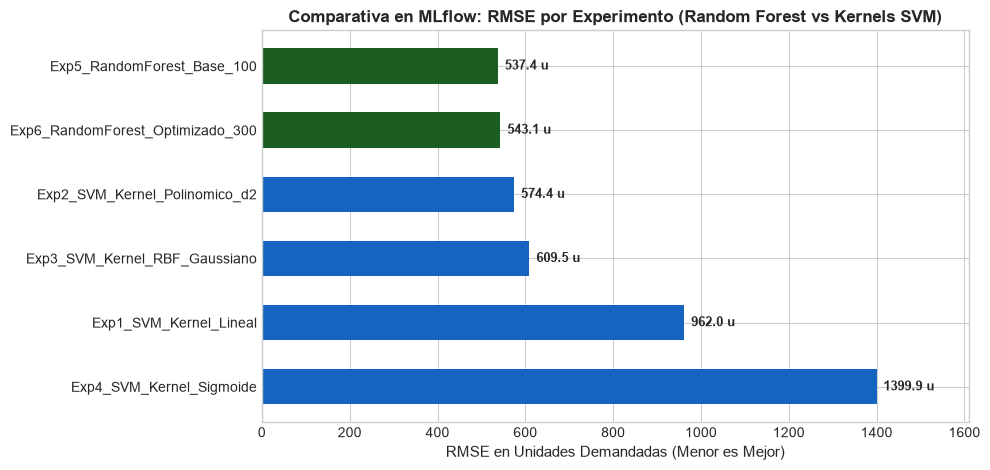

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.8))
palette = ['#1B5E20' if fam == 'RandomForest' else '#1565C0' for fam in df_experimentos['Familia']]

bars = ax.barh(df_experimentos['Experimento'].iloc[::-1], df_experimentos['RMSE'].iloc[::-1], color=palette[::-1], height=0.55)
ax.set_xlabel('RMSE en Unidades Demandadas (Menor es Mejor)', fontsize=11)
ax.set_title('Comparativa en MLflow: RMSE por Experimento (Random Forest vs Kernels SVM)', fontsize=12, fontweight='bold')

for bar in bars:
    w = bar.get_width()
    ax.annotate(f'{w:.1f} u', xy=(w, bar.get_y() + bar.get_height()/2), xytext=(5, 0),
                textcoords="offset points", ha='left', va='center', fontweight='bold', fontsize=9.5)

ax.set_xlim(0, df_experimentos['RMSE'].max() * 1.15)
plt.tight_layout()
comp_fig_path = os.path.join(ARTIFACTS_DIR, "comparativa_general_rmse.png")
plt.savefig(comp_fig_path, dpi=130)
plt.show()

### 5. Selección y Exportación de los Mejores Experimentos (Global, RF y SVM)
Se selecciona automáticamente el experimento con menor RMSE de cada familia y el mejor experimento global.
Se exportan los modelos ganadores (`mejor_modelo_rf.pkl` y `mejor_modelo_svm.pkl`) para el cuaderno de predicción.

In [5]:
mejor_global_row = df_experimentos.iloc[0]
mejor_rf_row = df_experimentos[df_experimentos['Familia'] == 'RandomForest'].iloc[0]
mejor_svm_row = df_experimentos[df_experimentos['Familia'] == 'SVM'].iloc[0]

# Guardamos copias dedicadas de los modelos ganadores para el Cuaderno 2 (Predicción)
with open(os.path.join(MODELS_DIR, "mejor_modelo_global.pkl"), "wb") as f:
    pickle.dump(modelos_guardados[mejor_global_row['Experimento']], f)

with open(os.path.join(MODELS_DIR, "mejor_modelo_rf.pkl"), "wb") as f:
    pickle.dump(modelos_guardados[mejor_rf_row['Experimento']], f)

with open(os.path.join(MODELS_DIR, "mejor_modelo_svm.pkl"), "wb") as f:
    pickle.dump(modelos_guardados[mejor_svm_row['Experimento']], f)

seleccion_info = {
    "mejor_experimento_global": mejor_global_row.to_dict(),
    "mejor_experimento_rf": mejor_rf_row.to_dict(),
    "mejor_experimento_svm": mejor_svm_row.to_dict()
}

with open(os.path.join(MODELS_DIR, "mejor_experimento_info.json"), "w", encoding="utf-8") as f:
    json.dump(seleccion_info, f, indent=2, ensure_ascii=False)

print("=" * 75)
print(f"MEJOR EXPERIMENTO GLOBAL : {mejor_global_row['Experimento']} (RMSE: {mejor_global_row['RMSE']} u | R²: {mejor_global_row['R2']})")
print(f"MEJOR EXPERIMENTO RF     : {mejor_rf_row['Experimento']} (RMSE: {mejor_rf_row['RMSE']} u | R²: {mejor_rf_row['R2']})")
print(f"MEJOR EXPERIMENTO SVM    : {mejor_svm_row['Experimento']} (RMSE: {mejor_svm_row['RMSE']} u | R²: {mejor_svm_row['R2']})")
print("=" * 75)
print("Modelos exportados en 'modelos/mejor_modelo_rf.pkl' y 'modelos/mejor_modelo_svm.pkl'.")

MEJOR EXPERIMENTO GLOBAL : Exp5_RandomForest_Base_100 (RMSE: 537.39 u | R²: 0.9305)
MEJOR EXPERIMENTO RF     : Exp5_RandomForest_Base_100 (RMSE: 537.39 u | R²: 0.9305)
MEJOR EXPERIMENTO SVM    : Exp2_SVM_Kernel_Polinomico_d2 (RMSE: 574.37 u | R²: 0.9206)
Modelos exportados en 'modelos/mejor_modelo_rf.pkl' y 'modelos/mejor_modelo_svm.pkl'.


### 6. Verificación de Consultas en la Base de Datos de MLflow
Consulta directa al cliente de MLflow confirmando que los 6 experimentos y sus artefactos están persistidos.
Para abrir el panel web ejecuta: `.\.venv\Scripts\python.exe -m mlflow server --backend-store-uri sqlite:///mlflow.db`

In [6]:
client = mlflow.tracking.MlflowClient()
exp_actual = client.get_experiment_by_name(EXPERIMENT_NAME)
runs_mlflow = client.search_runs(experiment_ids=[exp_actual.experiment_id], order_by=["metrics.rmse ASC"])

print(f"Experimento en MLflow: '{exp_actual.name}' (ID: {exp_actual.experiment_id}) | Total Runs guardados: {len(runs_mlflow)}")
print("-" * 85)
for idx, r in enumerate(runs_mlflow, 1):
    r_name = r.data.tags.get('mlflow.runName', r.info.run_id)
    r_rmse = r.data.metrics.get('rmse', 0.0)
    r_mae = r.data.metrics.get('mae', 0.0)
    r_r2 = r.data.metrics.get('r2_score', 0.0)
    print(f"{idx}. {r_name:<35} | RunID: {r.info.run_id[:8]}... | RMSE: {r_rmse:7.2f} u | MAE: {r_mae:6.2f} u | R²: {r_r2:.4f}")
print("-" * 85)

Experimento en MLflow: 'Experimentos_Demanda_RF_vs_SVM_Retail' (ID: 1) | Total Runs guardados: 6
-------------------------------------------------------------------------------------
1. Exp5_RandomForest_Base_100          | RunID: 70f69aef... | RMSE:  537.39 u | MAE: 309.93 u | R²: 0.9305
2. Exp6_RandomForest_Optimizado_300    | RunID: 42a56666... | RMSE:  543.08 u | MAE: 311.12 u | R²: 0.9290
3. Exp2_SVM_Kernel_Polinomico_d2       | RunID: 519dd65f... | RMSE:  574.37 u | MAE: 303.42 u | R²: 0.9206
4. Exp3_SVM_Kernel_RBF_Gaussiano       | RunID: a8e9e7cb... | RMSE:  609.45 u | MAE: 313.09 u | R²: 0.9106
5. Exp1_SVM_Kernel_Lineal              | RunID: c458cdc1... | RMSE:  961.96 u | MAE: 400.86 u | R²: 0.7771
6. Exp4_SVM_Kernel_Sigmoide            | RunID: 3d4865a9... | RMSE: 1399.89 u | MAE: 540.34 u | R²: 0.5281
-------------------------------------------------------------------------------------
